# 04 — Modeling, Evaluasi Bisnis, & Ekspor Artefak
Benchmark 5 kandidat model dengan `GroupKFold`, pelatihan `RandomForestRegressor` terbaik, analisis learning curve & residual, evaluasi per wilayah, dan ekspor bundle `.joblib` untuk [`app.py`](../app.py).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold

from house_price.config import BEST_RF_PARAMS, MODEL_ARTIFACT_PATH, RANDOM_STATE
from house_price.features.preprocessing import load_or_build_preprocessed_data
from house_price.models.train import (
    benchmark_models,
    tune_all_candidate_models,
    train_final_model,
    save_model_bundle,
)
from house_price.models.evaluate import (
    compute_regression_metrics,
    evaluate_by_wilayah,
    compute_learning_curve_stats,
)
from house_price.visualization.plots import (
    plot_learning_curve,
    plot_actual_vs_predicted,
    plot_feature_importance,
    plot_residuals,
)

prep = load_or_build_preprocessed_data()
print("Bentuk X_train_final & X_test_final:", prep.X_train_final.shape, prep.X_test_final.shape)

Bentuk X_train_final & X_test_final: (1107, 6) (277, 6)


## 1. Benchmark 5 Kandidat Model (Baseline Default vs Setelah Tuning, `GroupKFold`)

In [2]:
grup_cv = prep.train_df["deskripsi"].str.lower()
df_hasil = benchmark_models(prep.X_train_final, prep.y_train, groups=grup_cv, random_state=RANDOM_STATE)
display(df_hasil)

,Model,Baseline CV RMSE (log),CV RMSE (log),Delta RMSE,CV MAE (log),CV R2,Best Hyperparameters
0,Random Forest,0.15,0.14,-0.01,0.10,0.84,"bootstrap=True, max_depth=None, max_features='..."
1,Gradient Boosting,0.15,0.15,-0.01,0.10,0.83,"learning_rate=0.03, max_depth=None, max_featur..."
2,SVR (RBF),0.15,0.15,-0.00,0.11,0.81,"C=1.0, epsilon=0.01, gamma='auto', kernel='rbf'"
3,Ridge Regression,0.16,0.16,0.00,0.13,0.78,"alpha=1.0, fit_intercept=True, max_iter=None"
4,Linear Regression,0.16,0.16,0.00,0.13,0.78,"fit_intercept=True, positive=False"


## 2. Hyperparameter Tuning (Opsional) & Training Model Final
Set `RUN_GRID_SEARCH = True` jika ingin mengulang pencarian `GridSearchCV` pada seluruh 5 kandidat model (360 kombinasi / 1.800 fit dengan opsi `None`); default `False` agar cepat dan deterministik memakai `BEST_RF_PARAMS`.

In [3]:
RUN_GRID_SEARCH = False

if RUN_GRID_SEARCH:
    df_tune, best_estimators = tune_all_candidate_models(
        prep.X_train_final,
        prep.y_train,
        groups=grup_cv,
    )
    display(df_tune)
    best_name = str(df_tune.iloc[0]["Model"])
    model_terbaik = best_estimators[best_name]
    print(f"Model terbaik: {best_name} | Best params: {df_tune.iloc[0]['Best Hyperparameters']}")
else:
    print("Menggunakan BEST_RF_PARAMS:", BEST_RF_PARAMS)
    model_terbaik = train_final_model(prep.X_train_final, prep.y_train)

y_train_pred_log = model_terbaik.predict(prep.X_train_final)
y_test_pred_log = model_terbaik.predict(prep.X_test_final)

print(f"Training MSE: {mean_squared_error(prep.y_train, y_train_pred_log):.6f}")
print(f"Test MSE    : {mean_squared_error(prep.y_test, y_test_pred_log):.6f}")
print(f"Training R2 : {r2_score(prep.y_train, y_train_pred_log):.6f}")
print(f"Test R2     : {r2_score(prep.y_test, y_test_pred_log):.6f}")

Menggunakan BEST_RF_PARAMS: {'bootstrap': True, 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 300, 'n_jobs': -1, 'random_state': 42}


Training MSE: 0.009783
Test MSE    : 0.016186
Training R2 : 0.922110
Test R2     : 0.871399


## 3. Learning Curve & Metrik Evaluasi Bisnis (Rupiah & %)

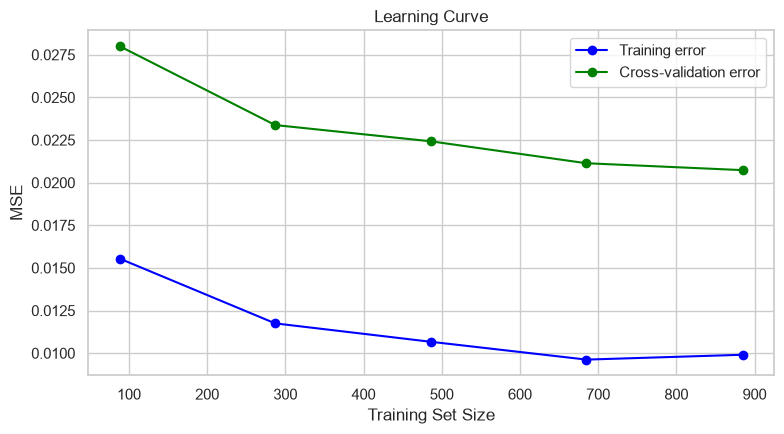

       EVALUASI PERFORMA MODEL (DATA TEST)
R2 Score (Kemampuan Prediksi) : 87.14%
Rata-rata Error (MAE Rupiah)  : Rp 354,905,653
RMSE Rupiah                   : Rp 840,362,311
Median Error Relatif (MdAPE)  : 14.17%
Rata-rata Error Relatif (MAPE): 21.56%


In [4]:
lc_estimator = train_final_model(prep.X_train_final, prep.y_train, params={"n_jobs": 1})
train_sizes, train_mean, test_mean = compute_learning_curve_stats(
    lc_estimator, prep.X_train_final, prep.y_train, cv=5, groups=grup_cv
)
fig = plot_learning_curve(train_sizes, train_mean, test_mean)
plt.show()

metrics = compute_regression_metrics(prep.y_test, y_test_pred_log)
print("=" * 45)
print("       EVALUASI PERFORMA MODEL (DATA TEST)")
print("=" * 45)
print(f"R2 Score (Kemampuan Prediksi) : {metrics['r2'] * 100:.2f}%")
print(f"Rata-rata Error (MAE Rupiah)  : Rp {metrics['mae_rupiah']:,.0f}")
print(f"RMSE Rupiah                   : Rp {metrics['rmse_rupiah']:,.0f}")
print(f"Median Error Relatif (MdAPE)  : {metrics['mdape']:.2f}%")
print(f"Rata-rata Error Relatif (MAPE): {metrics['mape']:.2f}%")
print("=" * 45)

## 4. Visualisasi Aktual vs Prediksi, Feature Importance, & Residual

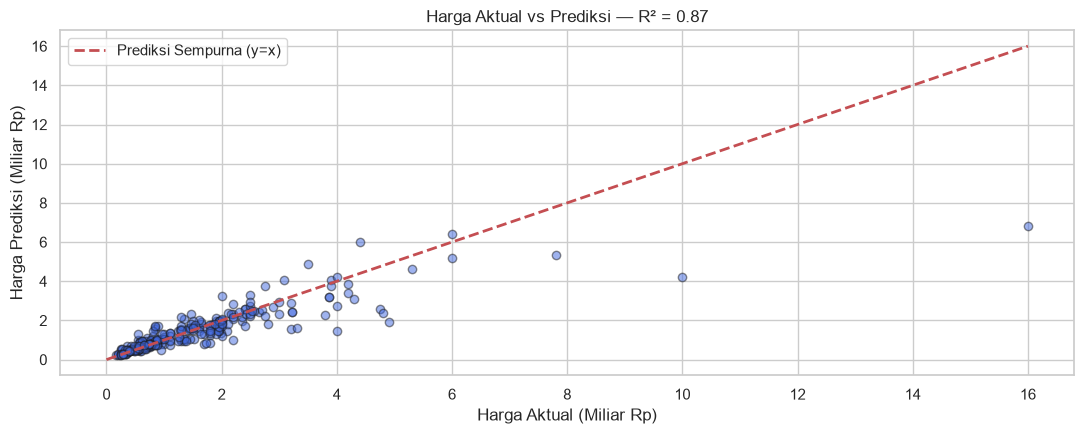

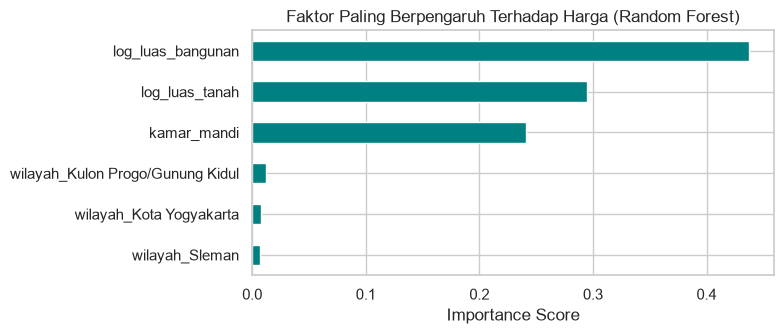

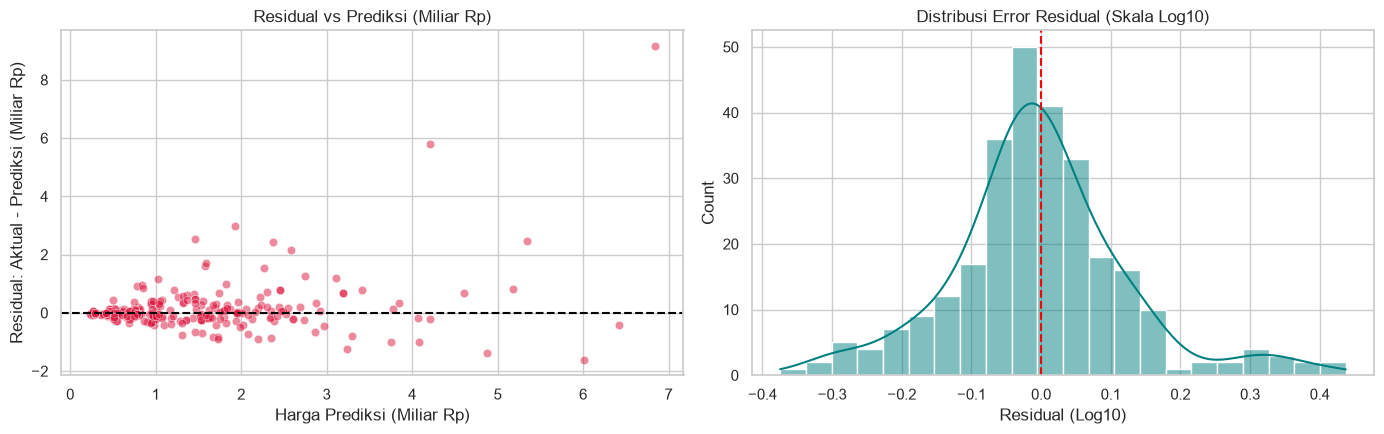

In [5]:
fig = plot_actual_vs_predicted(metrics["y_test_rupiah"], metrics["y_pred_rupiah"], metrics["r2"])
plt.show()

fig = plot_feature_importance(model_terbaik, prep.fitur_final)
plt.show()

residual_log = prep.y_test - y_test_pred_log
residual_rupiah = metrics["y_test_rupiah"] - metrics["y_pred_rupiah"]
fig = plot_residuals(metrics["y_pred_rupiah"], residual_rupiah, residual_log)
plt.show()

## 5. Evaluasi Tersegmentasi per Wilayah & Simpan Artefak `.joblib`

In [6]:
eval_wilayah = evaluate_by_wilayah(prep.test_df, metrics["y_pred_rupiah"])
eval_wilayah_fmt = eval_wilayah.copy()
eval_wilayah_fmt["MAE_Rupiah"] = eval_wilayah_fmt["MAE_Rupiah"].apply(lambda x: f"Rp {x:,.0f}")
eval_wilayah_fmt["MdAPE_Persen"] = eval_wilayah_fmt["MdAPE_Persen"].apply(lambda x: f"{x:.2f}%")
eval_wilayah_fmt["MAPE_Persen"] = eval_wilayah_fmt["MAPE_Persen"].apply(lambda x: f"{x:.2f}%")
display(eval_wilayah_fmt)

saved_path = save_model_bundle(model_terbaik, prep, path=MODEL_ARTIFACT_PATH)
print(f"Artefak model utama berhasil disimpan di: {saved_path}")

,wilayah_model,Jumlah_Sampel,MAE_Rupiah,MdAPE_Persen,MAPE_Persen
0,Bantul,44,"Rp 222,905,560",19.64%,28.61%
1,Kota Yogyakarta,26,"Rp 718,438,974",19.55%,32.57%
2,Kulon Progo/Gunung Kidul,7,"Rp 21,049,481",10.89%,7.27%
3,Sleman,200,"Rp 348,371,308",13.39%,19.08%


Artefak model utama berhasil disimpan di: D:\Dev\Python\Semester-5\DataScience\pPrediksi_Harga_Rumah_DS\model_artifacts\model_prediksi_rumah_jogja.joblib
